<h1>Визуализация данных</h1>
Цель визуализации данных </br>
Основная цель: </br>
Преобразование сырых данных в интуитивно понятные графические представления для:

- Выявления скрытых паттернов и трендов

- Обнаружения аномалий и выбросов

- Поддержки принятия решений на основе данных

- Упрощение анализа многомерных данных

Задачи визуализации </br>
1. Исследовательский анализ данных (EDA)</br>
- Понимание структуры и распределения данных</br>

- Выявление взаимосвязей между переменными</br>

- Обнаружение корреляций и зависимостей</br>

2. Коммуникация результатов</br>
- Донесение insights до stakeholders</br>
- Создание отчетов и дашбордов</br>
- Презентация выводов нетехнической аудитории</br>

3. Мониторинг и контроль</br>
- Выявление отклонений от нормы</br>
- Визуализация бизнес-показателей</br>

4. Поддержка ML-моделей</br>
- Анализ качества данных для обучения моделей</br>
- Визуализация результатов кластеризации</br>
- Интерпретация важности признаков</br>

Принципы хорошей визуализации</br>
1. Ясность и понятность</br>
Четкие заголовки и подписи</br>

Адекватные масштабы осей</br>

Минимум визуального шума</br>

2. Точность и достоверность</br>
Корректное отображение пропорций</br>

Отсутствие искажений данных</br>

Указание источников данных</br>

3. Эффективность коммуникации</br>
Выбор подходящего типа графика</br>

Использование цвета осмысленно</br>

Акцентирование важной информации</br>

4. Эстетика</br>
Сбалансированная композиция</br>

Гармоничная цветовая палитра</br>

Профессиональное оформление</br>

Инструменты и библиотеки </br>
Python библиотеки: </br>

```matplotlib``` - базовые графики</br>

```seaborn``` - статистическая визуализация</br>

```plotly``` - интерактивные графики</br>

```pandas``` - встроенные методы визуализации</br>

Типы графиков для разных задач:</br>

Сравнение: ```bar charts```, ```line plots```</br>

Распределение: ```histograms```, ```box plots```, ```violin plots```</br>

Взаимосвязи: ```scatter plots```, ```heatmaps```, ```pairplots```</br>

Композиция: ```pie charts```, ```stacked bar charts```</br>

Геоданные: ```choropleth maps```, ```scatter maps```</br>



<h2>Пример визуализации художественных произведений<h2> </br>
[Источник](https://epjdatascience.springeropen.com/articles/10.1140/epjds/s13688-016-0093-1/)

In [ ]:
# Установка razdel: ее нет в Colab по умолчанию
!pip install razdel

In [ ]:
# Регулярные выражения потребуются для очистки текста
import re

# Библиотека razdel потребуется для разбияния текста на предложения
# перед отправкой в нейросеть
from razdel import sentenize

# Без torch невозможна работа с нейросетями
import torch

# Библиотека transformers нужна для работы с нейросетями-трансформерами,
# которые мы будем использовать для анализа тональности
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Библиотека matplotlib позволит построить графики кривых тональности
from matplotlib import pyplot as plt

# Фильтр Савицкого-Голея понадобится нам для обработки результатов,
# которая будет описана позже
from scipy.signal import savgol_filter

In [ ]:
# Считаем текст из целевого файла text.txt
# Не забудьте загрузить его, используя вкладку "Файлы" слева сбоку
import pandas as pd

df = pd.read_csv('/content/reviews_prep.csv')
text = ' '.join(df['text'].dropna().astype(str))

In [ ]:
def clean_text(text: str) -> str:

    # Заменяем переносы строк на пробелы
    text = text.replace('\n', ' ')
    # Убираем лишние пробелы
    cleaned_text = re.sub(r'\s+', ' ', text).strip()

    return cleaned_text

In [ ]:
# Очистим текст
cleaned_text = clean_text(text)

In [ ]:
# Разобьем текст на предложения и загрузим их в список
sentences = []
for substring in list(sentenize(cleaned_text)):
    sentences.append(substring.text)

In [ ]:
# Загрузим модель с сайта HuggingFace и создадим ее экземпляр
# Возможно модели нужно будет скачаться в Colab. Подождите немного...
model_checkpoint = 'cointegrated/rubert-tiny-sentiment-balanced'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint)
if torch.cuda.is_available():
    model.cuda()

# Сложная функция, которая заставит модель работать
def estimate_sentiment(messages: list) -> list:
    sentiment_out = []
    for text in messages:
        with torch.no_grad():
            inputs = tokenizer(text, return_tensors='pt', truncation=True, padding=True).to(model.device)
            proba = torch.sigmoid(model(**inputs).logits).cpu().numpy()[0]
            sentiment_out.append(proba.dot([-1, 0, 1]))
    return sentiment_out

config.json:   0%|          | 0.00/884 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/377 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/241k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/468k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 47.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/57 [00:00<?, ?it/s]

In [ ]:
# Произведем нейросетевую оценку тональности
sentiments = estimate_sentiment(sentences)

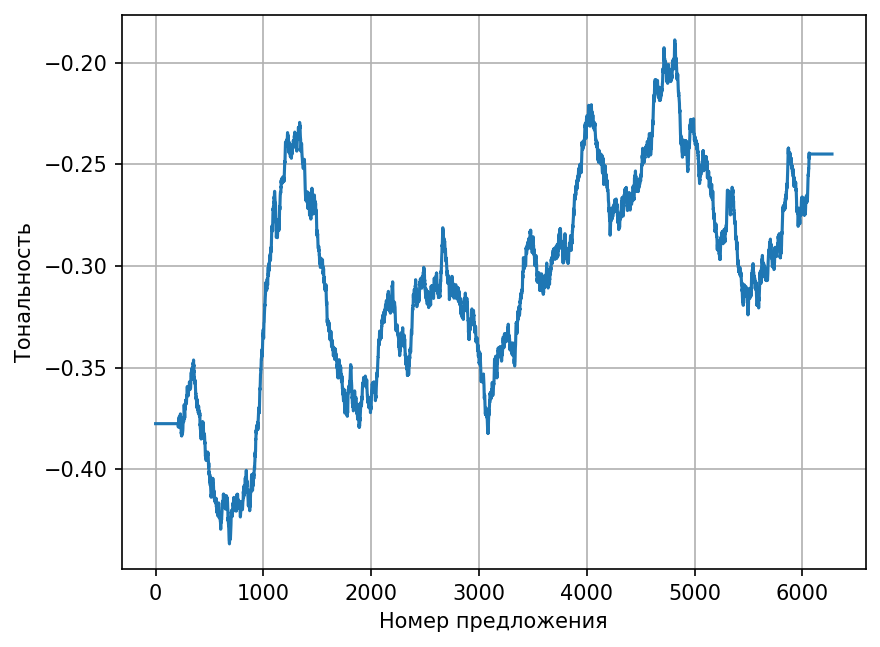

In [ ]:
# Произведем фильтрацию сигнала фильтром Савицкого-Голея
filtered_sentiments = savgol_filter(sentiments, window_length=len(sentiments)//15, polyorder=0)

# Построим график кривой эмоциональной тональности
plt.figure(dpi=150)
plt.plot(filtered_sentiments)
plt.xlabel('Номер предложения')
plt.ylabel('Тональность')
plt.grid()

In [ ]:
# Ансамблевый фильтр
def ensemble_filter(data: list, n_filters=100, polyorder=0, **savgol_args) -> list:
    """
    Применяет ансамблевый фильтр к вхожным данным

    Parameters:
    data (list): входной массив данных
    n_filters (int, optional): число фильтров участвующих в сглаживании
    """
    filt = 0
    start = len(data)//10
    stop = len(data)//4
    step = (stop-start)//n_filters
    if step == 0:
        step = 1
    # Варьируем размер окна и усредняем результат
    for window_size in range(start, stop, step):
        res = savgol_filter(data, window_length=window_size, polyorder=polyorder, **savgol_args)
        filt += res
    return filt/n_filters

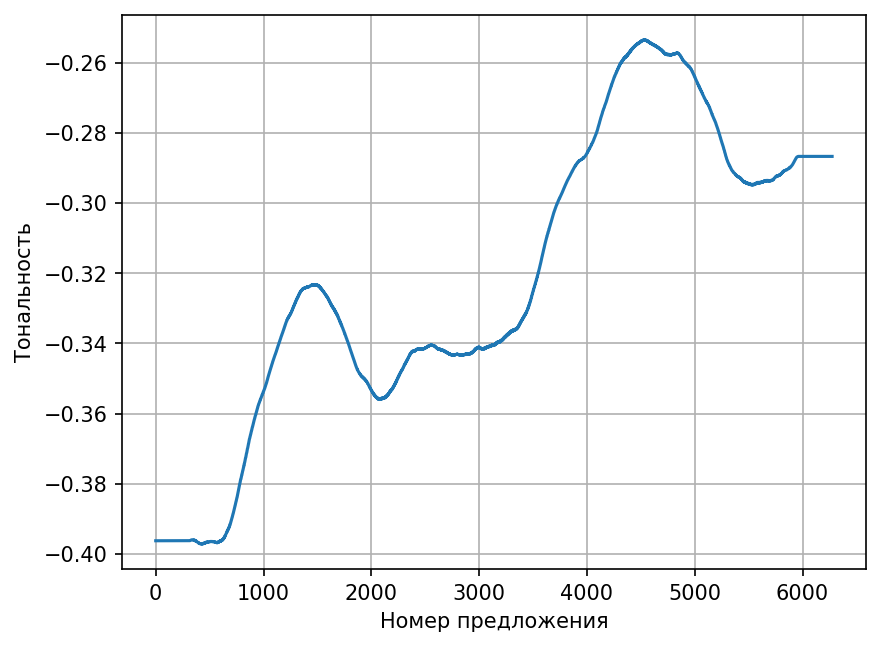

In [ ]:
# Произведем фильтрацию сигнала ансамблевым фильтром
filtered_sentiments = ensemble_filter(sentiments, polyorder=0)

# Построим график кривой эмоциональной тональности
plt.figure(dpi=150)
plt.plot(filtered_sentiments)
plt.xlabel('Номер предложения')
plt.ylabel('Тональность')
plt.grid()

In [ ]:
Анализ отзывов

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

import nltk

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/reviews_prep.csv')
print(df.head(5))

                                                text label_text  label     id  \
0  всё пришло спасибо. только немного короче чем ...   positive      2  64971   
1  The color of the dress is not the same as in t...    neutral      1  34896   
2  Заказывала белый цвет, пришёл какой то персико...    neutral      1  46253   
3  Приятное к телу. Но в бюсте на размер больше. ...   negative      0  19034   
4                Не пришла деньги через спор вернули    neutral      1  36063   

                                          clean_text  
0  всё прийти спасибо немного короче ожидать всё ...  
1  the color of the dress is not the same as in t...  
2  заказывать белый цвет прийти персиковый ответи...  
3  приятный тело бюст оформить январь прибыть январь  
4                                прийти спор вернуть  


In [ ]:
#рандомизаторы
import random
from datetime import datetime, timedelta
def rndate():
  start_date = datetime(2024, 1, 1)
  end_date = datetime(2025, 1, 1)
  # 2. Вычислите общее количество дней в диапазоне
  days_in_range = (end_date - start_date).days
  # 3. Сгенерируйте случайное количество дней в диапазоне
  random_days = random.randint(0, days_in_range)
  # 4. Создайте случайную дату, добавив случайное число дней к начальной дате
  random_date = start_date + timedelta(days=random_days)
  # 5. Теперь random_date содержит случайную дату, которую можно вставить в колонку
  return(random_date)

def rndrate_pos():
  random_rate = random.randint(4, 5)
  return(random_rate)

def rndrate_neg():
  random_rate = random.randint(1, 2)
  return(random_rate)
def rndrate_net():
  random_rate = random.randint(3, 4)
  return(random_rate)

from datetime import time
# def generate_random_time():
#     hour = random.randint(0, 23)
#     minute = random.randint(0, 59)
#     second = random.randint(0, 59)
#     return time(hour, minute, second)
def generate_random_time():
    hour = random.randint(0, 23)
    minute = random.randint(0, 59)
    second = random.randint(0, 59)
    return time(hour, minute, second)

In [ ]:
from datetime import datetime, timedelta
import random

def rndatetime():
    # Генерация случайной даты
    start_date = datetime(2024, 1, 1)
    end_date = datetime(2025, 1, 1)
    days_in_range = (end_date - start_date).days
    random_days = random.randint(0, days_in_range)
    random_date = start_date + timedelta(days=random_days)

    # Генерация случайного времени
    random_hour = random.randint(0, 23)
    random_minute = random.randint(0, 59)
    random_second = random.randint(0, 59)

    # Объединяем дату и время
    random_datetime = random_date.replace(hour=random_hour, minute=random_minute, second=random_second)

    return random_datetime

In [ ]:
df['data'] = None
for i in range(len(df['label'])):
  df.loc[i,'data'] = rndatetime()
  i=+1


In [ ]:
df['rating'] = None
for i in range(len(df['label'])):
  if df['label'][i]==2:
    df.loc[i,'rating'] = rndrate_pos()
  elif df['label'][i]==0:
    df.loc[i,'rating'] = rndrate_neg()
  else:
    df.loc[i,'rating'] = rndrate_net()

In [ ]:
df['label'][0]

np.int64(2)

In [ ]:
df.head()

,text,label_text,label,id,clean_text,data,rating
0,всё пришло спасибо. только немного короче чем ...,positive,2,64971,всё прийти спасибо немного короче ожидать всё ...,2024-04-09 07:42:09,5
1,The color of the dress is not the same as in t...,neutral,1,34896,the color of the dress is not the same as in t...,2024-10-26 12:18:14,3
2,"Заказывала белый цвет, пришёл какой то персико...",neutral,1,46253,заказывать белый цвет прийти персиковый ответи...,2024-10-12 07:20:42,4
3,Приятное к телу. Но в бюсте на размер больше. ...,negative,0,19034,приятный тело бюст оформить январь прибыть январь,2024-03-27 06:49:29,2
4,Не пришла деньги через спор вернули,neutral,1,36063,прийти спор вернуть,2024-09-23 01:11:28,3


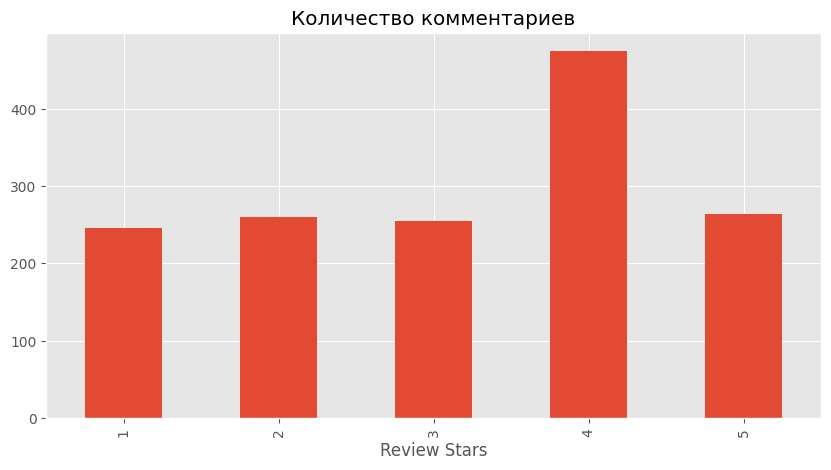

In [ ]:
ax = df['rating'].value_counts().sort_index() \
    .plot(kind='bar',
          title='Количество комментариев',
          figsize=(10, 5))
ax.set_xlabel('Review Stars')
plt.show()

<Axes: xlabel='label', ylabel='count'>

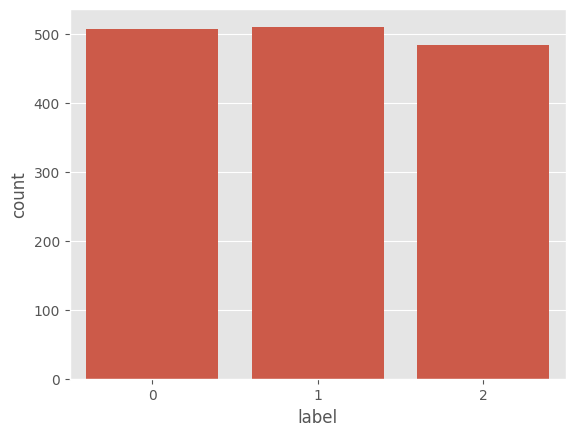

In [ ]:
import seaborn as sb
#распределение отзывов одинаковое
sb.countplot(x='label', data=df)

In [ ]:
# Преобразуем колонку data в datetime и извлекаем компоненты времени
df['data'] = pd.to_datetime(df['data'])
df['date'] = df['data'].dt.date
df['month'] = df['data'].dt.month
df['day_of_week'] = df['data'].dt.day_name()
df['hour'] = df['data'].dt.hour
df['day_of_week_num'] = df['data'].dt.dayofweek  # для правильной сортировки

In [ ]:
df.head()

,text,label_text,label,id,clean_text,data,rating,date,month,day_of_week,hour,day_of_week_num
0,всё пришло спасибо. только немного короче чем ...,positive,2,64971,всё прийти спасибо немного короче ожидать всё ...,2024-04-09 07:42:09,5,2024-04-09,4,Tuesday,7,1
1,The color of the dress is not the same as in t...,neutral,1,34896,the color of the dress is not the same as in t...,2024-10-26 12:18:14,3,2024-10-26,10,Saturday,12,5
2,"Заказывала белый цвет, пришёл какой то персико...",neutral,1,46253,заказывать белый цвет прийти персиковый ответи...,2024-10-12 07:20:42,4,2024-10-12,10,Saturday,7,5
3,Приятное к телу. Но в бюсте на размер больше. ...,negative,0,19034,приятный тело бюст оформить январь прибыть январь,2024-03-27 06:49:29,2,2024-03-27,3,Wednesday,6,2
4,Не пришла деньги через спор вернули,neutral,1,36063,прийти спор вернуть,2024-09-23 01:11:28,3,2024-09-23,9,Monday,1,0


In [ ]:
df.describe()

,label,id,data,month,hour,day_of_week_num
count,1500.000000,1500.000000,1500,1500.000000,1500.000000,1500.000000
mean,0.985333,41275.360667,2024-07-07 20:28:13.674667008,6.683333,11.182667,2.866667
min,0.000000,98.000000,2024-01-01 01:20:34,1.000000,0.000000,0.000000
25%,0.000000,18808.500000,2024-04-07 08:34:45.750000128,4.000000,5.000000,1.000000
50%,1.000000,40943.500000,2024-07-13 01:46:19.500000,7.000000,11.000000,3.000000
75%,2.000000,63756.000000,2024-10-08 22:51:11.249999872,10.000000,17.000000,5.000000
max,2.000000,82889.000000,2025-01-01 17:07:01,12.000000,23.000000,6.000000
std,0.812542,24610.947405,NaN,3.485468,7.004618,1.998888


In [ ]:
print(df['data'].dtype)
print(df['hour'].dtype)

datetime64[ns]
int32


In [ ]:
# df['time'] = pd.to_datetime(df['hour'])

In [ ]:
# Настройка стиля графиков
plt.style.use('seaborn-v0_8')
fig = plt.figure(figsize=(20, 16))

<Figure size 2000x1600 with 0 Axes>

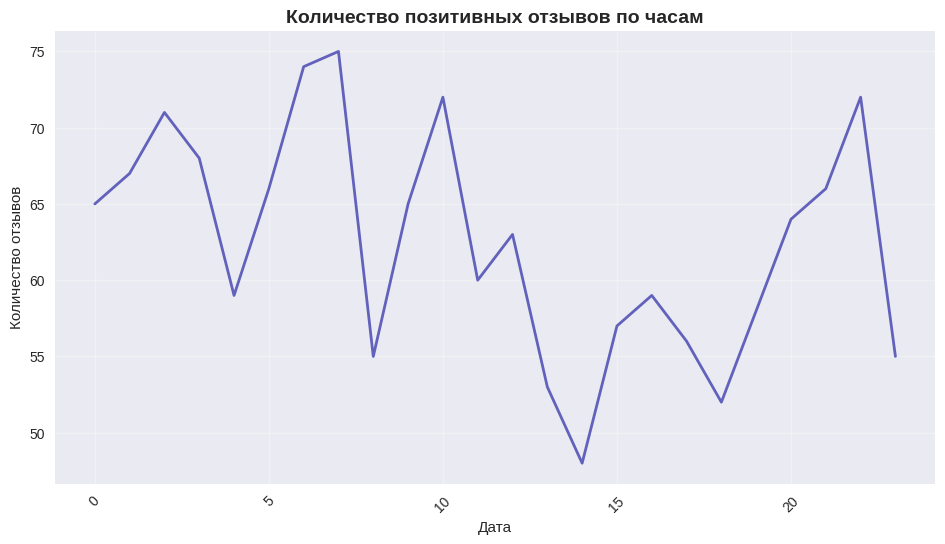

In [ ]:
# 1. Активность позитивных отзывов по времени
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 1)
daily_positive = df.groupby('hour').size()
plt.plot(daily_positive.index, daily_positive.values, linewidth=2, alpha=0.7, color='#2828a7')
plt.title('Количество позитивных отзывов по часам', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Количество отзывов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

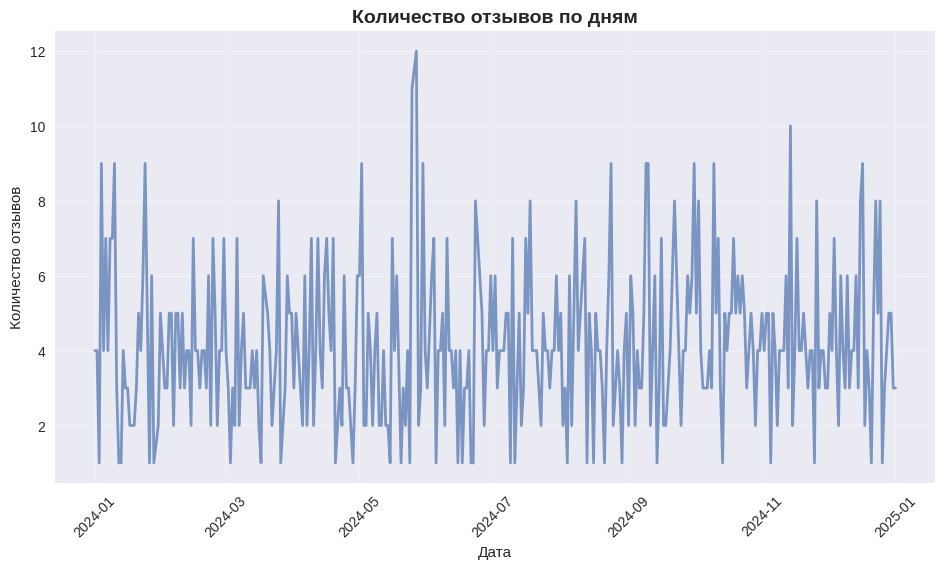

In [ ]:
# 1. Активность отзывов по времени
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 1)
daily_reviews = df.groupby('date').size()
plt.plot(daily_reviews.index, daily_reviews.values, linewidth=2, alpha=0.7)
plt.title('Количество отзывов по дням', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Количество отзывов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

/tmp/ipykernel_584/733688182.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  heatmap_data = heatmap_data.fillna(0).astype(float)


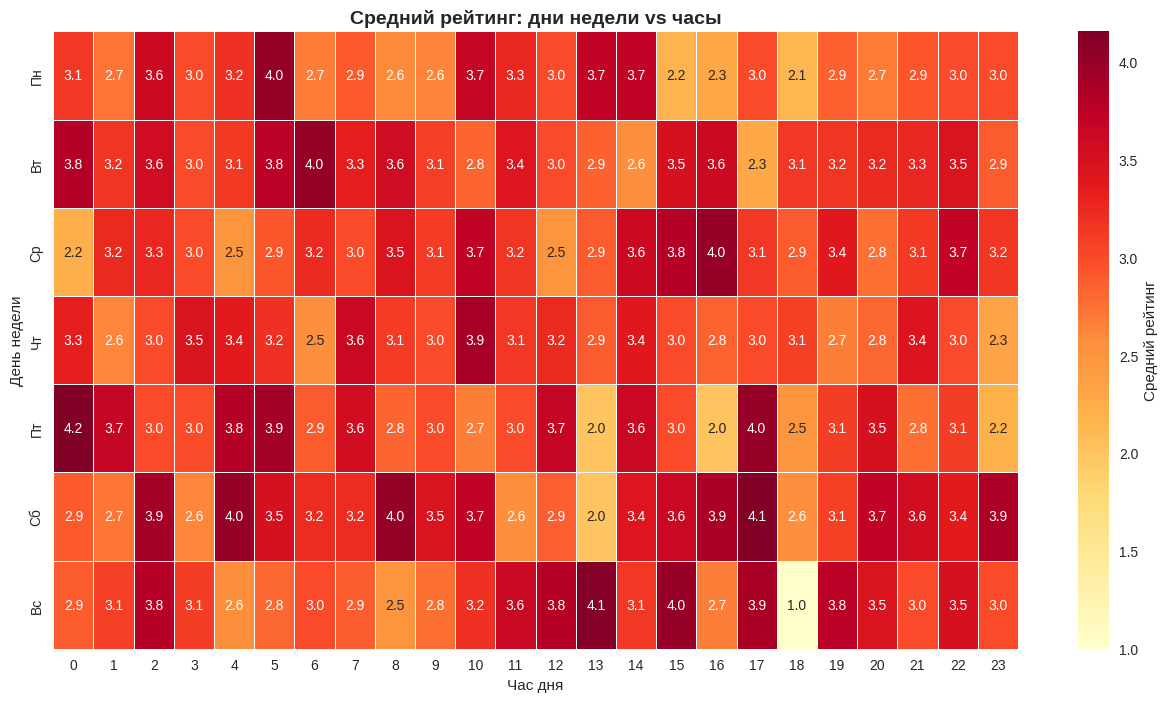

In [ ]:
# 6. Тепловая карта: рейтинг по дням недели и часам
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 6)
# Создаем числовую колонку для правильной сортировки дней недели
df['day_of_week_ordered'] = df['data'].dt.dayofweek
heatmap_data = df.pivot_table(values='rating', index='day_of_week_ordered',
                             columns='hour', aggfunc='mean')

# Заполняем пропущенные значения и преобразуем к float
heatmap_data = heatmap_data.fillna(0).astype(float)

# Переименовываем индексы для читаемости
day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
heatmap_data.index = day_names

# Создаем маску для скрытия нулевых значений (если хотим скрыть пустые ячейки)
mask = heatmap_data == 0

sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='.1f',
            cbar_kws={'label': 'Средний рейтинг'}, linewidths=0.5,
            mask=mask)  # опционально: скрыть нулевые значения
plt.title('Средний рейтинг: дни недели vs часы', fontsize=14, fontweight='bold')
plt.xlabel('Час дня')
plt.ylabel('День недели')

plt.tight_layout()
plt.show()

([<matplotlib.axis.XTick at 0x7d98598a2e90>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20'),
  Text(21, 0, '21'),
  Text(22, 0, '22'),
  Text(23, 0, '23')])

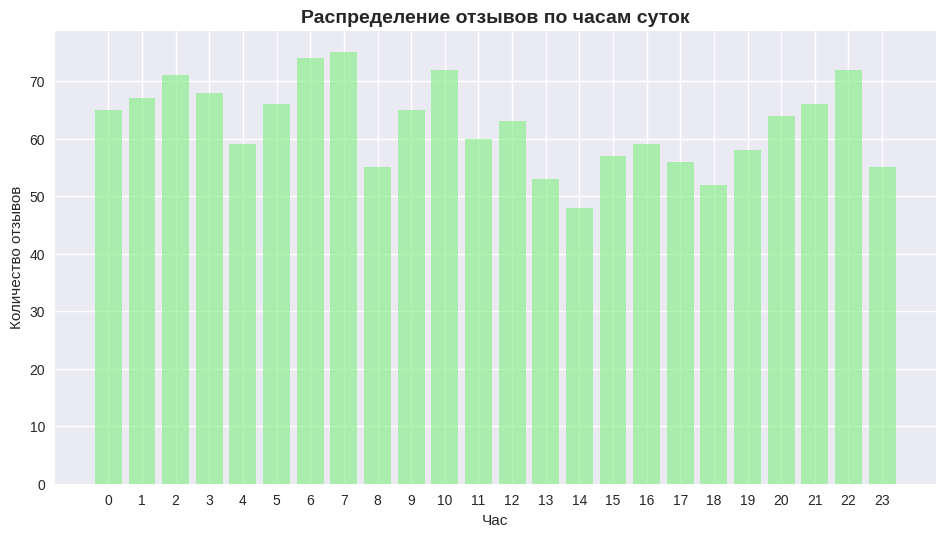

In [ ]:
# 3. Распределение по часам
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 3)
hour_counts = df['hour'].value_counts().sort_index()
plt.bar(hour_counts.index, hour_counts.values, color='lightgreen', alpha=0.7)
plt.title('Распределение отзывов по часам суток', fontsize=14, fontweight='bold')
plt.xlabel('Час')
plt.ylabel('Количество отзывов')
plt.xticks(range(0, 24))

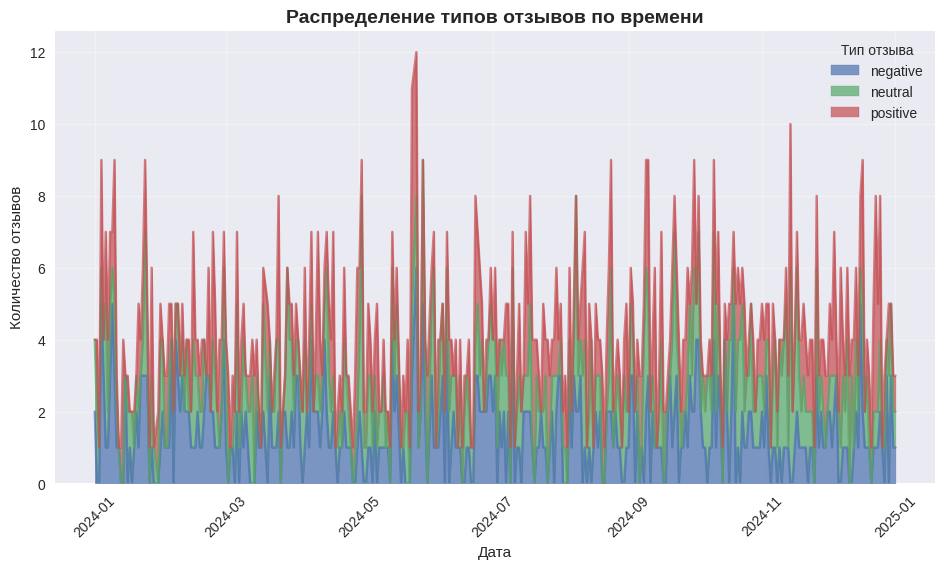

In [ ]:
# 4. Распределение типов отзывов по времени (стек area chart)
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 4)
sentiment_over_time = df.groupby(['date', 'label_text']).size().unstack(fill_value=0)
sentiment_over_time.plot(kind='area', stacked=True, alpha=0.7, ax=plt.gca())
plt.title('Распределение типов отзывов по времени', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Количество отзывов')
plt.legend(title='Тип отзыва')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

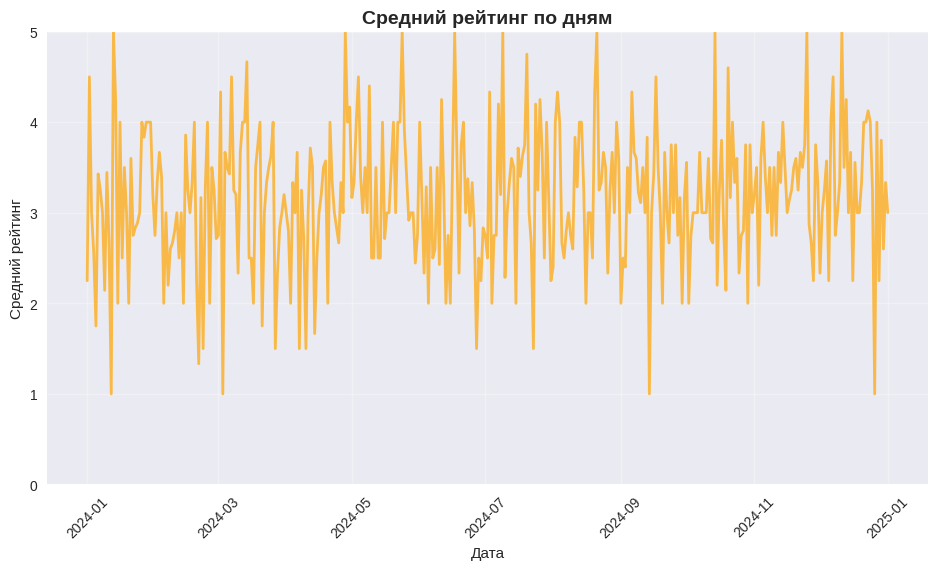

In [ ]:
# 5. Средний рейтинг по времени
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 5)
rating_over_time = df.groupby('date')['rating'].mean()
plt.plot(rating_over_time.index, rating_over_time.values, linewidth=2, color='orange', alpha=0.7)
plt.title('Средний рейтинг по дням', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Средний рейтинг')
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

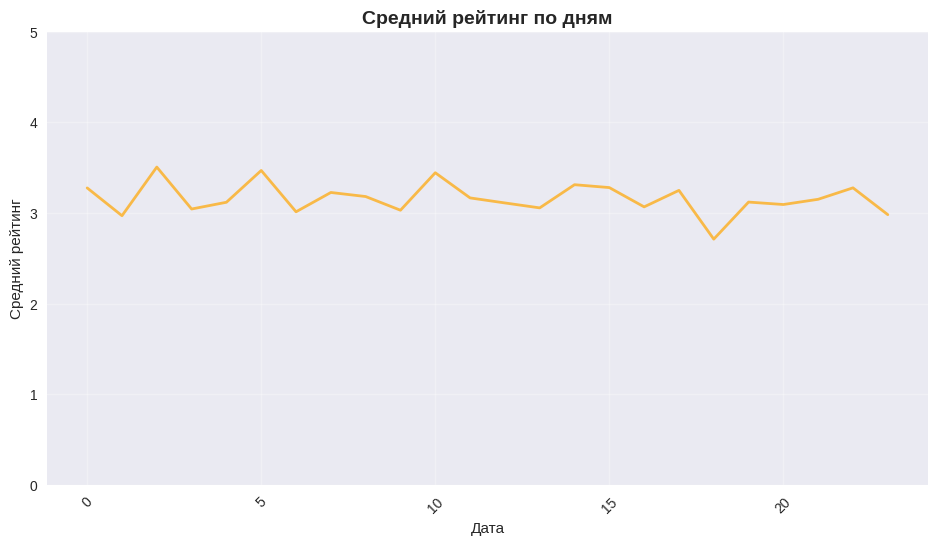

In [ ]:
# 5. Средний рейтинг по времени
plt.figure(figsize=(25, 20))
plt.subplot(3, 2, 5)
rating_over_time = df.groupby('hour')['rating'].mean()
plt.plot(rating_over_time.index, rating_over_time.values, linewidth=2, color='orange', alpha=0.7)
plt.title('Средний рейтинг по дням', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Средний рейтинг')
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

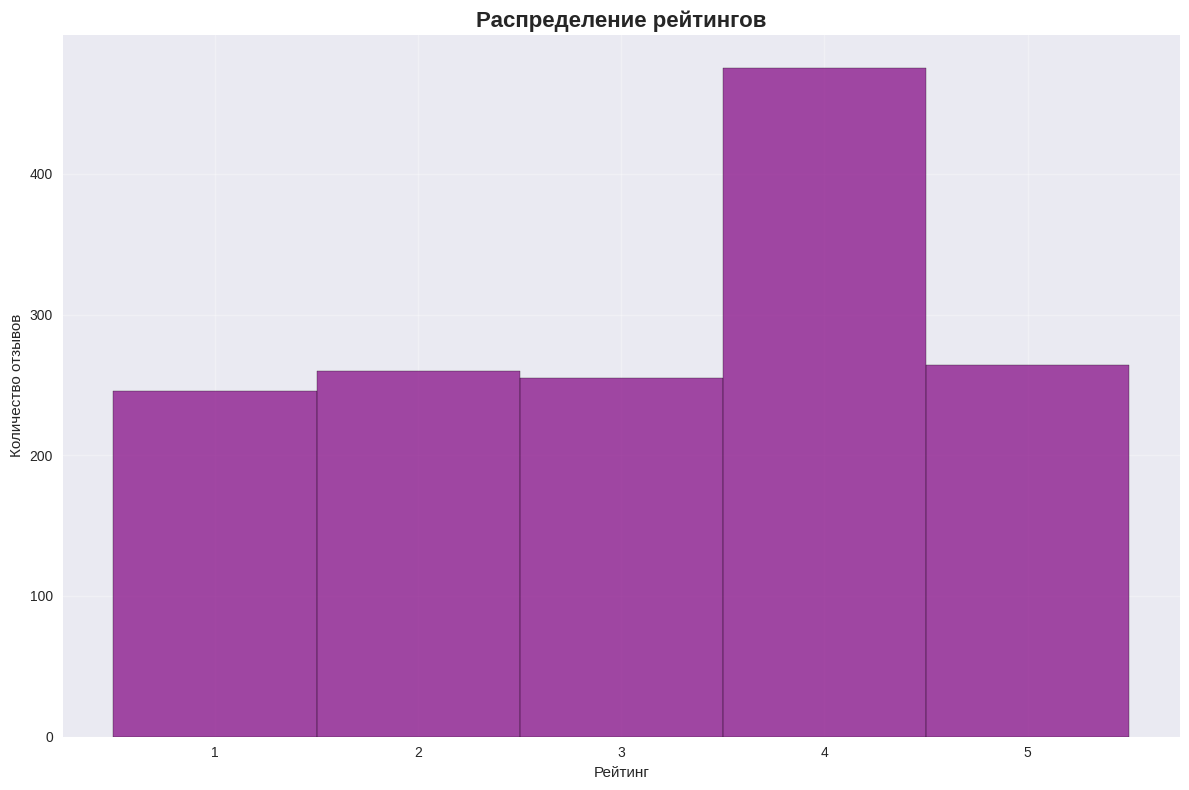

In [ ]:
# Дополнительные визуализации
plt.figure(figsize=(12, 8))

# Распределение рейтингов
plt.hist(df['rating'], bins=5, range=(0.5, 5.5), alpha=0.7, color='purple', edgecolor='black')
plt.title('Распределение рейтингов', fontsize=16, fontweight='bold')
plt.xlabel('Рейтинг')
plt.ylabel('Количество отзывов')
plt.xticks(range(1, 6))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



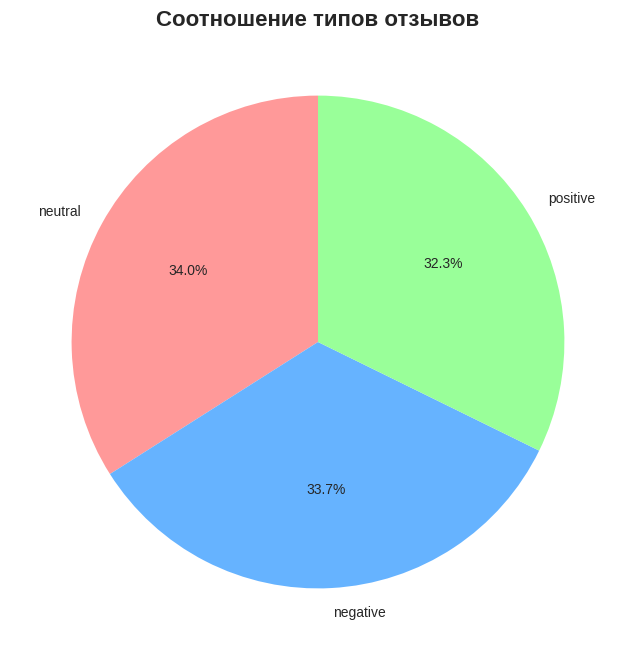

In [ ]:
plt.figure(figsize=(10, 8))
sentiment_counts = df['label_text'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99']
plt.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90)
plt.title('Соотношение типов отзывов', fontsize=16, fontweight='bold')
plt.show()

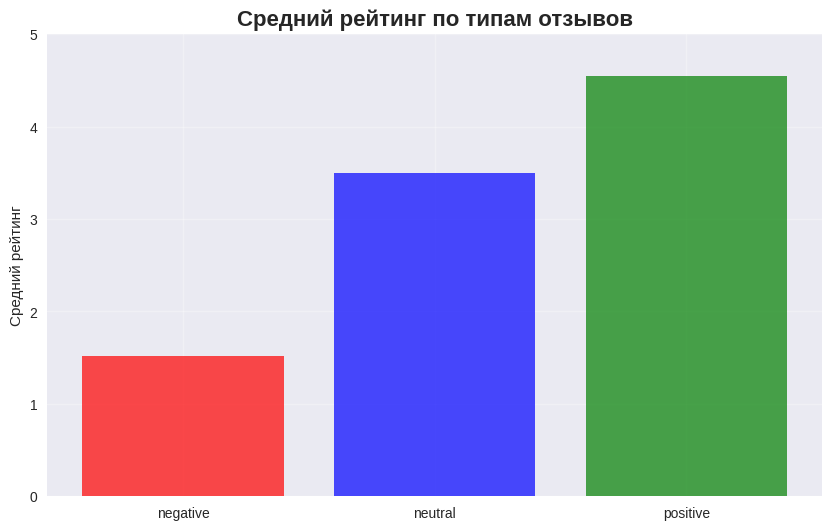

In [ ]:
# Средний рейтинг
plt.figure(figsize=(10, 6))
rating_by_sentiment = df.groupby('label_text')['rating'].mean()
plt.bar(rating_by_sentiment.index, rating_by_sentiment.values,
        color=['red', 'blue', 'green'], alpha=0.7)
plt.title('Средний рейтинг по типам отзывов', fontsize=16, fontweight='bold')
plt.ylabel('Средний рейтинг')
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.show()

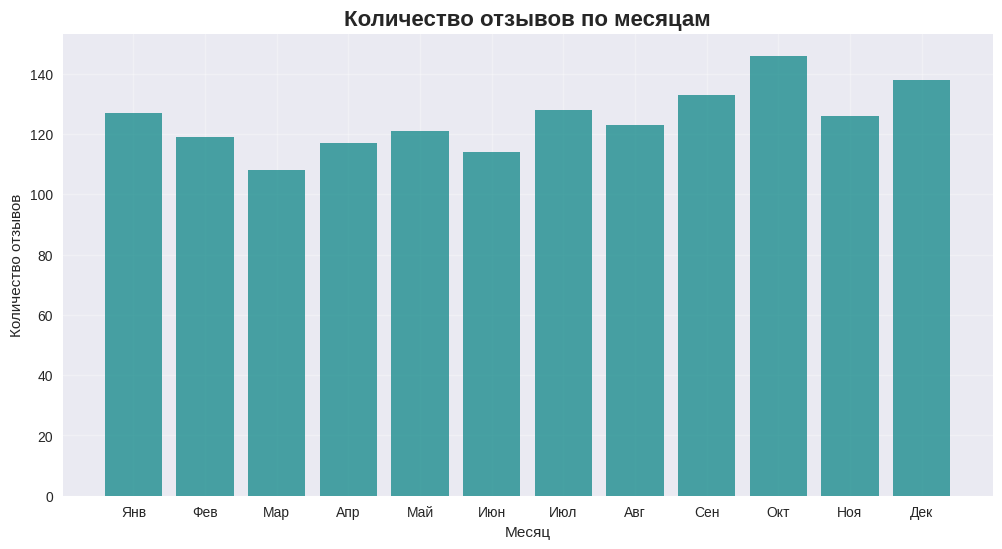

In [ ]:
# По месяцам
plt.figure(figsize=(12, 6))
df['month'] = pd.to_datetime(df['data']).dt.month
month_counts = df['month'].value_counts().sort_index()
month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
plt.bar(month_counts.index, month_counts.values, color='teal', alpha=0.7)
plt.title('Количество отзывов по месяцам', fontsize=16, fontweight='bold')
plt.xlabel('Месяц')
plt.ylabel('Количество отзывов')
plt.xticks(range(1, 13), month_names)
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("=" * 50)
print("СТАТИСТИЧЕСКАЯ СВОДКА:")
print("=" * 50)
print(f"Всего отзывов: {len(df)}")
print(f"Период данных: от {df['data'].min()} до {df['data'].max()}")
print(f"Дней с отзывами: {df['data'].nunique()}")
print("\nРаспределение по типам:")
print(df['label_text'].value_counts())
print(f"\nСредний рейтинг: {df['rating'].mean():.2f}")
print(f"Медианный рейтинг: {df['rating'].median():.2f}")
print(f"\nСамый активный час: {df['hour'].mode().iloc[0]}:00")
print(f"Самый активный день недели: {df['day_of_week'].mode().iloc[0]}")

СТАТИСТИЧЕСКАЯ СВОДКА:
Всего отзывов: 1500
Период данных: от 2024-01-01 01:20:34 до 2025-01-01 17:07:01
Дней с отзывами: 1500

Распределение по типам:
label_text
neutral     510
negative    506
positive    484
Name: count, dtype: int64

Средний рейтинг: 3.17
Медианный рейтинг: 3.00

Самый активный час: 7:00
Самый активный день недели: Monday


In [ ]:
# Продвинутый анализ

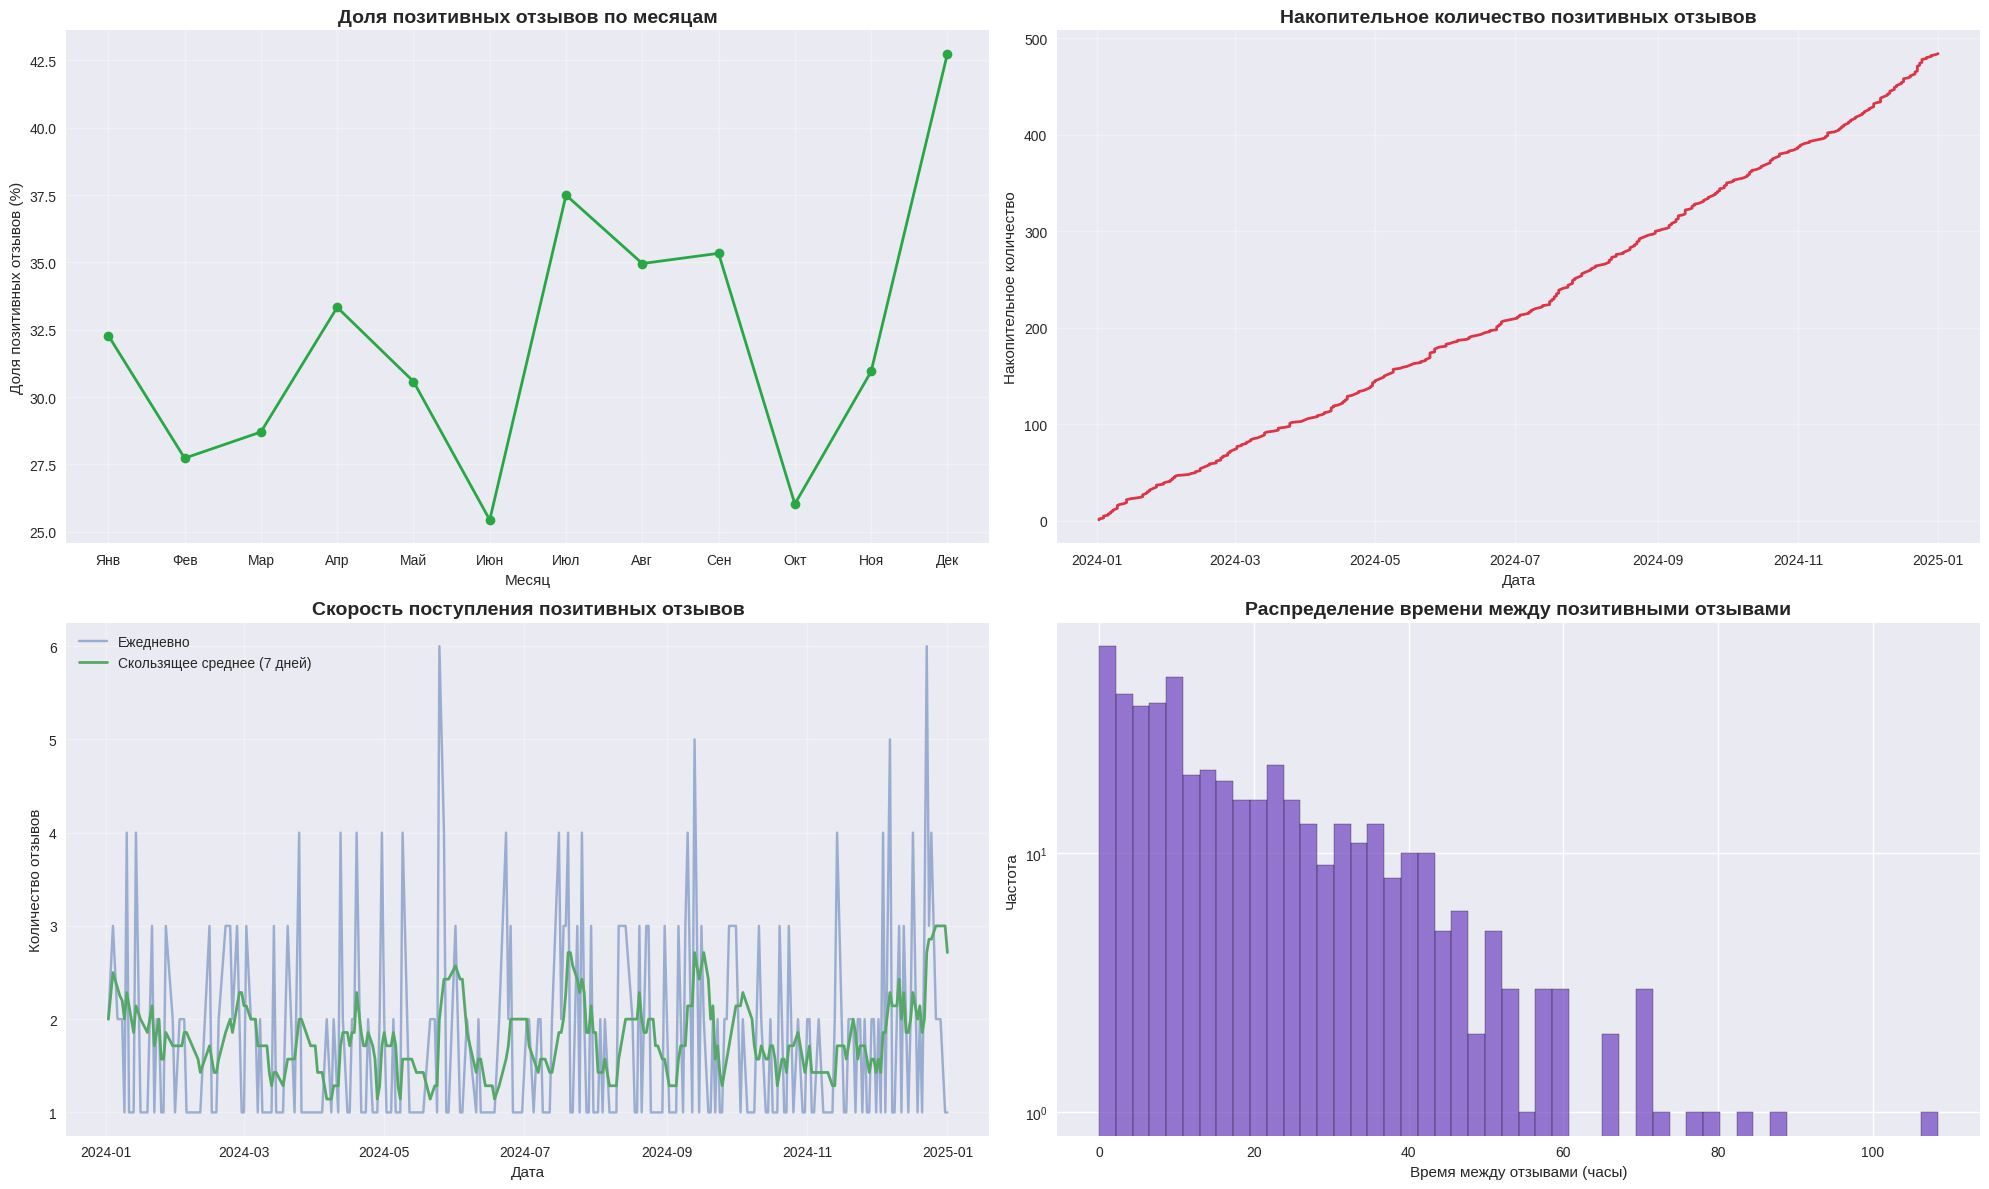

In [ ]:
positive_df = df[df['label_text'] == 'positive'].copy()
# Сезонность позитивных отзывов
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))

# 1.1 Сезонность по месяцам (сравнение с общим трендом)
monthly_total = df.groupby(df['data'].dt.month).size()
monthly_positive = positive_df.groupby(positive_df['data'].dt.month).size()
monthly_ratio = (monthly_positive / monthly_total * 100).reindex(range(1, 13), fill_value=0)

ax1.plot(monthly_ratio.index, monthly_ratio.values, marker='o', linewidth=2, color='#28A745')
ax1.set_title('Доля позитивных отзывов по месяцам', fontsize=14, fontweight='bold')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Доля позитивных отзывов (%)')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
ax1.grid(True, alpha=0.3)

# 1.2 Накопительная сумма позитивных отзывов
positive_df_sorted = positive_df.sort_values('data')
positive_df_sorted['cumulative'] = range(1, len(positive_df_sorted) + 1)

ax2.plot(positive_df_sorted['date'], positive_df_sorted['cumulative'], linewidth=2, color='#DC3545')
ax2.set_title('Накопительное количество позитивных отзывов', fontsize=14, fontweight='bold')
ax2.set_xlabel('Дата')
ax2.set_ylabel('Накопительное количество')
ax2.grid(True, alpha=0.3)

# 1.3 Скорость поступления позитивных отзывов (скользящее среднее)
daily_positive = positive_df.groupby('date').size()
daily_positive_ma = daily_positive.rolling(window=7, min_periods=1).mean()

ax3.plot(daily_positive.index, daily_positive.values, alpha=0.5, label='Ежедневно')
ax3.plot(daily_positive_ma.index, daily_positive_ma.values, linewidth=2, label='Скользящее среднее (7 дней)')
ax3.set_title('Скорость поступления позитивных отзывов', fontsize=14, fontweight='bold')
ax3.set_xlabel('Дата')
ax3.set_ylabel('Количество отзывов')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 1.4 Распределение длительности между позитивными отзывами
positive_df_sorted['time_diff'] = positive_df_sorted['data'].diff().dt.total_seconds() / 3600  # в часах

ax4.hist(positive_df_sorted['time_diff'].dropna(), bins=50, color='#6F42C1', alpha=0.7, edgecolor='black')
ax4.set_title('Распределение времени между позитивными отзывами', fontsize=14, fontweight='bold')
ax4.set_xlabel('Время между отзывами (часы)')
ax4.set_ylabel('Частота')
ax4.set_yscale('log')  # логарифмическая шкала для лучшей визуализации

plt.tight_layout()
plt.show()

In [ ]:
positive_df_sorted.head()

,text,label_text,label,id,clean_text,data,rating,date,month,day_of_week,hour,day_of_week_num,day_of_week_ordered,cumulative,time_diff
1346,"Очень крепкие чашки,держатся отлично!",positive,2,67522,крепкий чашкидержаться отлично,2024-01-02 10:03:27,5,2024-01-02,1,Tuesday,10,1,1,1,NaN
1146,"выглядит не плохо, цвет как на картинке. тонка...",positive,2,81570,выглядеть плохо цвет картинка тонкий лето пойти,2024-01-02 18:08:06,5,2024-01-02,1,Tuesday,18,1,1,2,8.077500
704,Всё отлично. Ткань приятная к телу. Соответств...,positive,2,78677,всё отлично ткань приятный тело соответствоват...,2024-01-04 11:24:19,5,2024-01-04,1,Thursday,11,3,3,3,41.270278
450,Куртка хорошая. Продавец общительный. Рекоменд...,positive,2,81448,куртка хороший общительный рекомендовать продавец,2024-01-04 11:27:04,5,2024-01-04,1,Thursday,11,3,3,4,0.045833
1001,"Беру уже третью, хорошая. Быстрая доставка.",positive,2,73806,брать третий хороший быстрый,2024-01-04 20:52:16,5,2024-01-04,1,Thursday,20,3,3,5,9.420000


In [ ]:
#2. Анализ текстовой информации
from wordcloud import WordCloud
from collections import Counter
import re

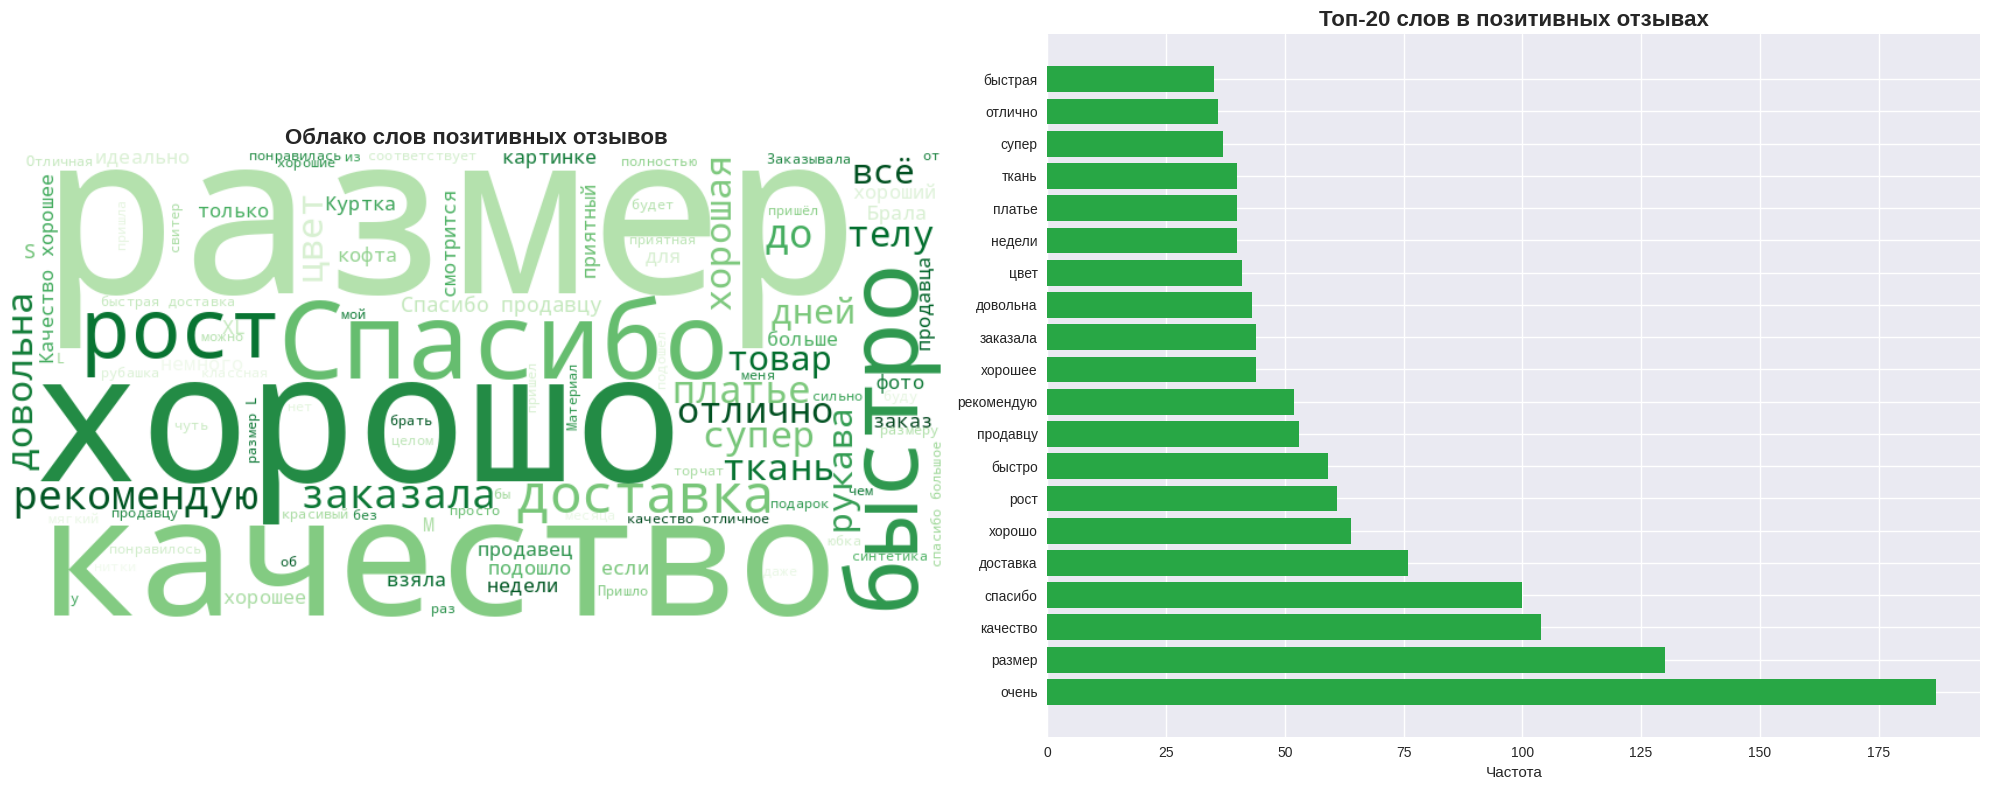

In [ ]:
# 2.1 Облако слов для позитивных отзывов
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Собираем все тексты позитивных отзывов
all_positive_text = ' '.join(positive_df['text'].astype(str).values)

# Создаем облако слов
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='Greens',
    max_words=100,
    stopwords=['это', 'очень', 'все', 'так', 'что', 'который', 'свой', 'и', 'то', 'а', 'на', 'не', 'но', 'за', 'как', 'к', 'по', 'я', 'мне', 'с', 'в']  # добавьте нужные стоп-слова
).generate(all_positive_text)

ax1.imshow(wordcloud, interpolation='bilinear')
ax1.set_title('Облако слов позитивных отзывов', fontsize=16, fontweight='bold')
ax1.axis('off')

# 2.2 Топ-20 слов в позитивных отзывах
words = re.findall(r'\b[а-яё]{4,}\b', all_positive_text.lower())  # слова от 4 букв
word_freq = Counter(words)
top_words = word_freq.most_common(20)

ax2.barh([word[0] for word in top_words], [word[1] for word in top_words], color='#28A745')
ax2.set_title('Топ-20 слов в позитивных отзывах', fontsize=16, fontweight='bold')
ax2.set_xlabel('Частота')

plt.tight_layout()
plt.show()


In [ ]:
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
df['review_len'] = df['text'].apply(lambda x: len(str(x)))

In [ ]:
df.head()

,text,label_text,label,id,clean_text,data,rating,date,month,day_of_week,hour,day_of_week_num,day_of_week_ordered,word_count,review_len
0,всё пришло спасибо. только немного короче чем ...,positive,2,64971,всё прийти спасибо немного короче ожидать всё ...,2024-04-09 07:42:09,5,2024-04-09,4,Tuesday,7,1,1,12,69
1,The color of the dress is not the same as in t...,neutral,1,34896,the color of the dress is not the same as in t...,2024-10-26 12:18:14,3,2024-10-26,10,Saturday,12,5,5,33,151
2,"Заказывала белый цвет, пришёл какой то персико...",neutral,1,46253,заказывать белый цвет прийти персиковый ответи...,2024-10-12 07:20:42,4,2024-10-12,10,Saturday,7,5,5,29,185
3,Приятное к телу. Но в бюсте на размер больше. ...,negative,0,19034,приятный тело бюст оформить январь прибыть январь,2024-03-27 06:49:29,2,2024-03-27,3,Wednesday,6,2,2,16,91
4,Не пришла деньги через спор вернули,neutral,1,36063,прийти спор вернуть,2024-09-23 01:11:28,3,2024-09-23,9,Monday,1,0,0,6,35


/tmp/ipykernel_584/1628301439.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='review_len', width=0.5, palette='viridis', data=df)


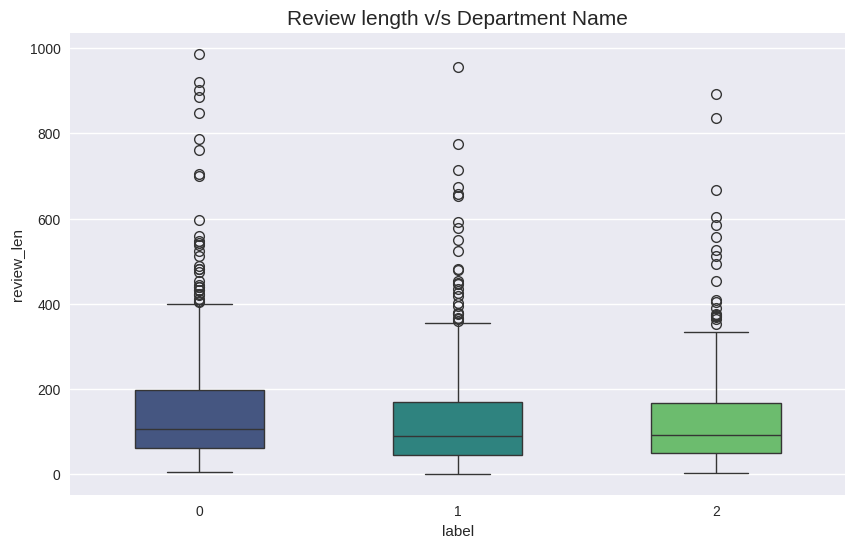

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='label', y='review_len', width=0.5, palette='viridis', data=df)
plt.title('Review length v/s Department Name', size=15)
plt.show()

/tmp/ipykernel_584/2831436689.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='word_count', width=0.5, palette='viridis', data=df)


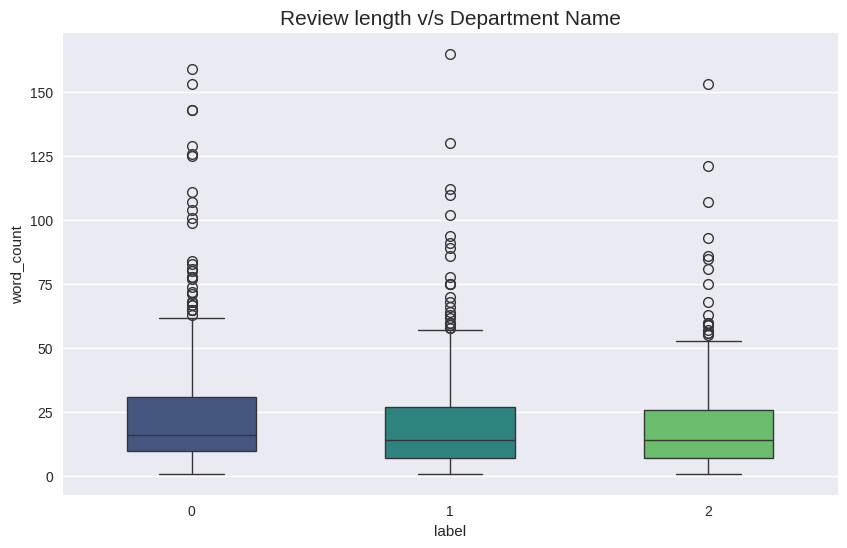

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='label', y='word_count', width=0.5, palette='viridis', data=df)
plt.title('Review length v/s Department Name', size=15)
plt.show()

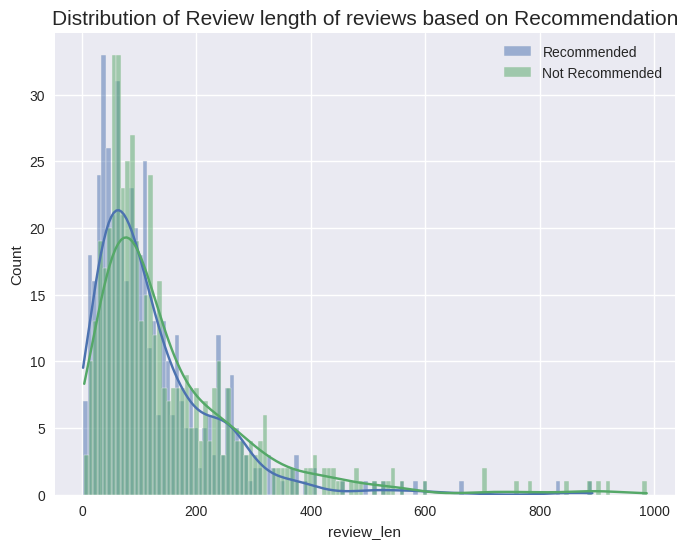

In [ ]:
recommended = df.loc[df['label'] == 2, 'review_len']
not_recommended = df.loc[df['label'] == 0, 'review_len']

plt.figure(figsize=(8, 6))
sns.histplot(x=recommended,  kde=True, label='Recommended', binwidth=8)
sns.histplot(x=not_recommended, kde=True, label='Not Recommended', binwidth=8)
plt.title('Distribution of Review length of reviews based on Recommendation', size=15)
plt.legend()
plt.show()

In [ ]:
# 3. Анализ взаимосвязей

Типы данных перед очисткой:
rating         object
day_num         int32
hour_num        int32
month_num       int32
text_length     int64
dtype: object

Размер датасета до очистки: 15000
Размер датасета после очистки: 15000


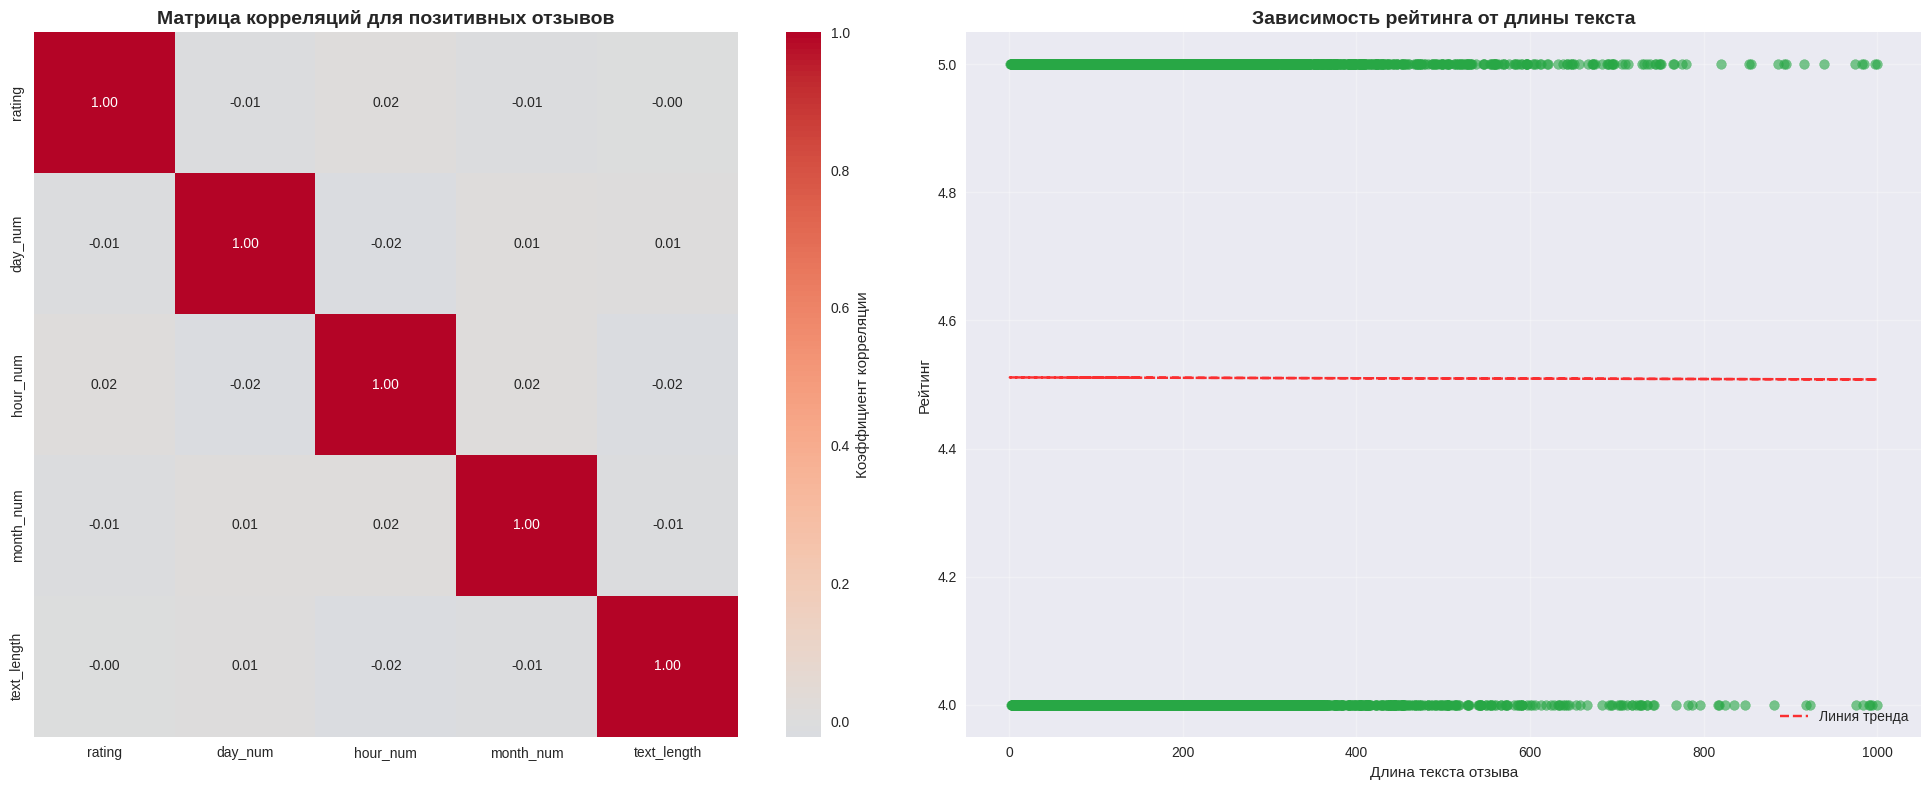

In [ ]:
# 3.1 Матрица корреляций для числовых признаков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Создаем числовые признаки для анализа
analysis_df = positive_df.copy()

# Используем только данные из колонки data (без колонки hour)
analysis_df['day_num'] = analysis_df['data'].dt.dayofweek
analysis_df['hour_num'] = analysis_df['data'].dt.hour
analysis_df['month_num'] = analysis_df['data'].dt.month
analysis_df['text_length'] = analysis_df['text'].str.len()

# Проверяем типы данных и очищаем от нечисловых значений
print("Типы данных перед очисткой:")
print(analysis_df[['rating', 'day_num', 'hour_num', 'month_num', 'text_length']].dtypes)

# Преобразуем все колонки к числовому типу и удаляем NaN
numeric_columns = ['rating', 'day_num', 'hour_num', 'month_num', 'text_length']
for col in numeric_columns:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors='coerce')

# Удаляем строки с NaN значениями
analysis_df_clean = analysis_df[numeric_columns].dropna()

print(f"\nРазмер датасета до очистки: {len(analysis_df)}")
print(f"Размер датасета после очистки: {len(analysis_df_clean)}")

# Матрица корреляций
corr_matrix = analysis_df_clean.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=ax1,
            square=True, fmt='.2f', cbar_kws={'label': 'Коэффициент корреляции'})
ax1.set_title('Матрица корреляций для позитивных отзывов', fontsize=14, fontweight='bold')

# 3.2 Длина текста vs рейтинг
if len(analysis_df_clean) > 1:
    ax2.scatter(analysis_df_clean['text_length'], analysis_df_clean['rating'], alpha=0.6, color='#28A745')
    ax2.set_xlabel('Длина текста отзыва')
    ax2.set_ylabel('Рейтинг')
    ax2.set_title('Зависимость рейтинга от длины текста', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)

    # Добавляем линию тренда
    try:
        z = np.polyfit(analysis_df_clean['text_length'], analysis_df_clean['rating'], 1)
        p = np.poly1d(z)
        ax2.plot(analysis_df_clean['text_length'], p(analysis_df_clean['text_length']), "r--", alpha=0.8, label='Линия тренда')
        ax2.legend()
    except Exception as e:
        print(f"Ошибка при построении линии тренда: {e}")
else:
    ax2.text(0.5, 0.5, 'Недостаточно данных', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('Зависимость рейтинга от длины текста', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# 4. Сравнительный анализ

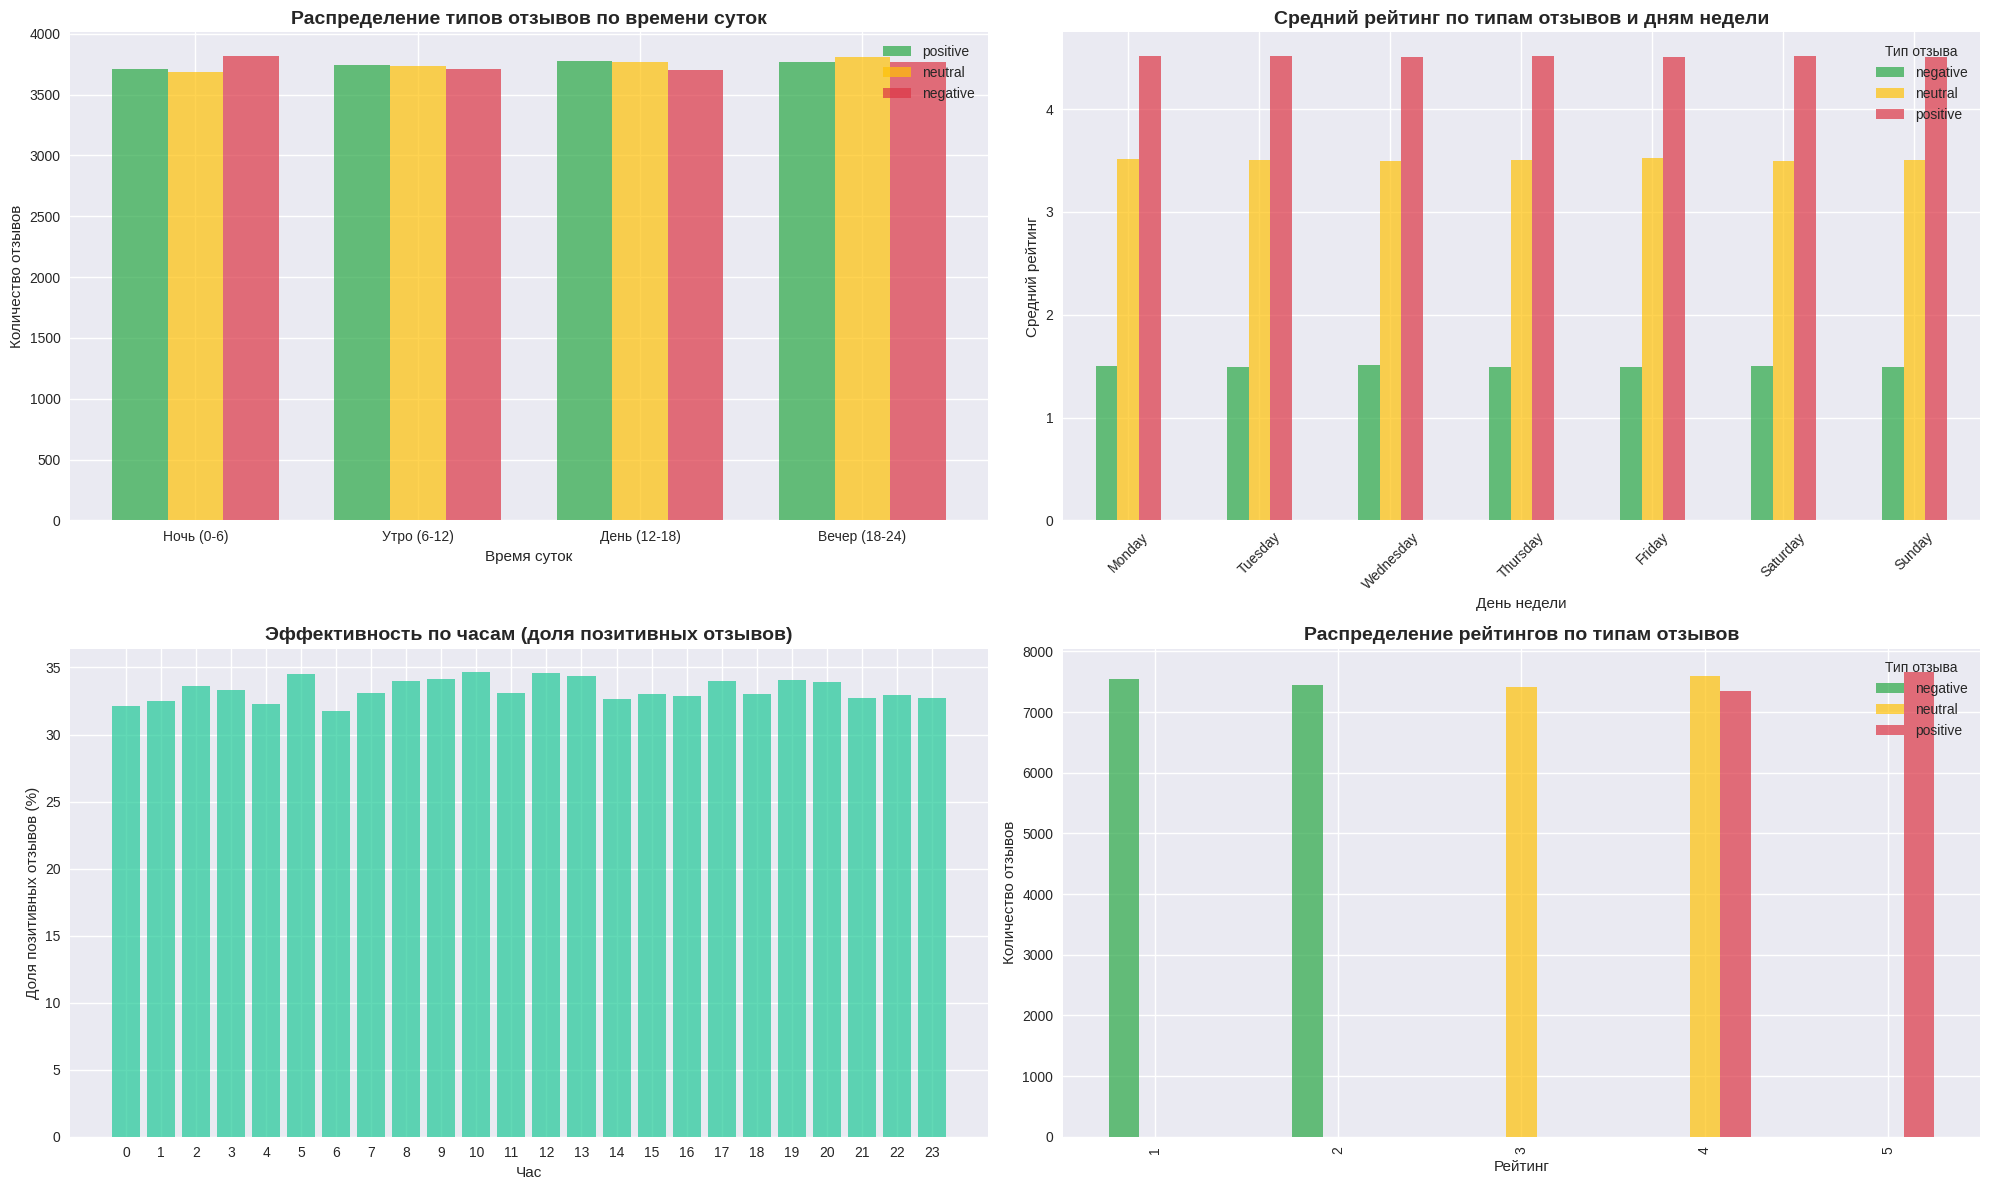

In [ ]:
# 4.1 Сравнение с негативными и нейтральными отзывами
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))
# Распределение по времени суток для всех типов отзывов
time_slots = ['Ночь (0-6)', 'Утро (6-12)', 'День (12-18)', 'Вечер (18-24)']
time_ranges = [(0, 6), (6, 12), (12, 18), (18, 24)]
# Определяем правильный порядок дней недели
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Средний рейтинг по типам отзывов и дням недели
sentiment_rating_by_day = df.groupby(['day_of_week', 'label_text'])['rating'].mean().unstack()
sentiment_rating_by_day = sentiment_rating_by_day.reindex(day_order)
sentiment_time_data = []
for sentiment in df['label_text'].unique():
    sentiment_data = []
    sentiment_df = df[df['label_text'] == sentiment]
    for start, end in time_ranges:
        count = len(sentiment_df[(sentiment_df['data'].dt.hour >= start) &
                               (sentiment_df['data'].dt.hour < end)])
        sentiment_data.append(count)
    sentiment_time_data.append(sentiment_data)

x = np.arange(len(time_slots))
width = 0.25

for i, sentiment in enumerate(df['label_text'].unique()):
    offset = width * i
    ax1.bar(x + offset, sentiment_time_data[i], width, label=sentiment,
           color=['#28A745', '#FFC107', '#DC3545'][i], alpha=0.7)

ax1.set_xlabel('Время суток')
ax1.set_ylabel('Количество отзывов')
ax1.set_title('Распределение типов отзывов по времени суток', fontsize=14, fontweight='bold')
ax1.set_xticks(x + width)
ax1.set_xticklabels(time_slots)
ax1.legend()

# 4.2 Средний рейтинг по типам отзывов и дням недели
sentiment_rating_by_day = df.groupby(['day_of_week', 'label_text'])['rating'].mean().unstack()
sentiment_rating_by_day = sentiment_rating_by_day.reindex(day_order)

sentiment_rating_by_day.plot(kind='bar', ax=ax2, color=['#28A745', '#FFC107', '#DC3545'], alpha=0.7)
ax2.set_title('Средний рейтинг по типам отзывов и дням недели', fontsize=14, fontweight='bold')
ax2.set_xlabel('День недели')
ax2.set_ylabel('Средний рейтинг')
ax2.legend(title='Тип отзыва')
ax2.tick_params(axis='x', rotation=45)


# 4.3 Эффективность по часам (доля позитивных отзывов)
hourly_effectiveness = []
hours_range = range(24)

for hour in hours_range:
    hour_total = len(df[df['data'].dt.hour == hour])
    hour_positive = len(positive_df[positive_df['data'].dt.hour == hour])
    effectiveness = (hour_positive / hour_total * 100) if hour_total > 0 else 0
    hourly_effectiveness.append(effectiveness)

ax3.bar(hours_range, hourly_effectiveness, color='#20C997', alpha=0.7)
ax3.set_title('Эффективность по часам (доля позитивных отзывов)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Час')
ax3.set_ylabel('Доля позитивных отзывов (%)')
ax3.set_xticks(range(0, 24))

# 4.4 Сравнение распределения рейтингов
rating_comparison = df.groupby(['rating', 'label_text']).size().unstack(fill_value=0)

rating_comparison.plot(kind='bar', ax=ax4, color=['#28A745', '#FFC107', '#DC3545'], alpha=0.7)
ax4.set_title('Распределение рейтингов по типам отзывов', fontsize=14, fontweight='bold')
ax4.set_xlabel('Рейтинг')
ax4.set_ylabel('Количество отзывов')
ax4.legend(title='Тип отзыва')

plt.tight_layout()
plt.show()

In [ ]:
# 5. Продвинутые временные анализы

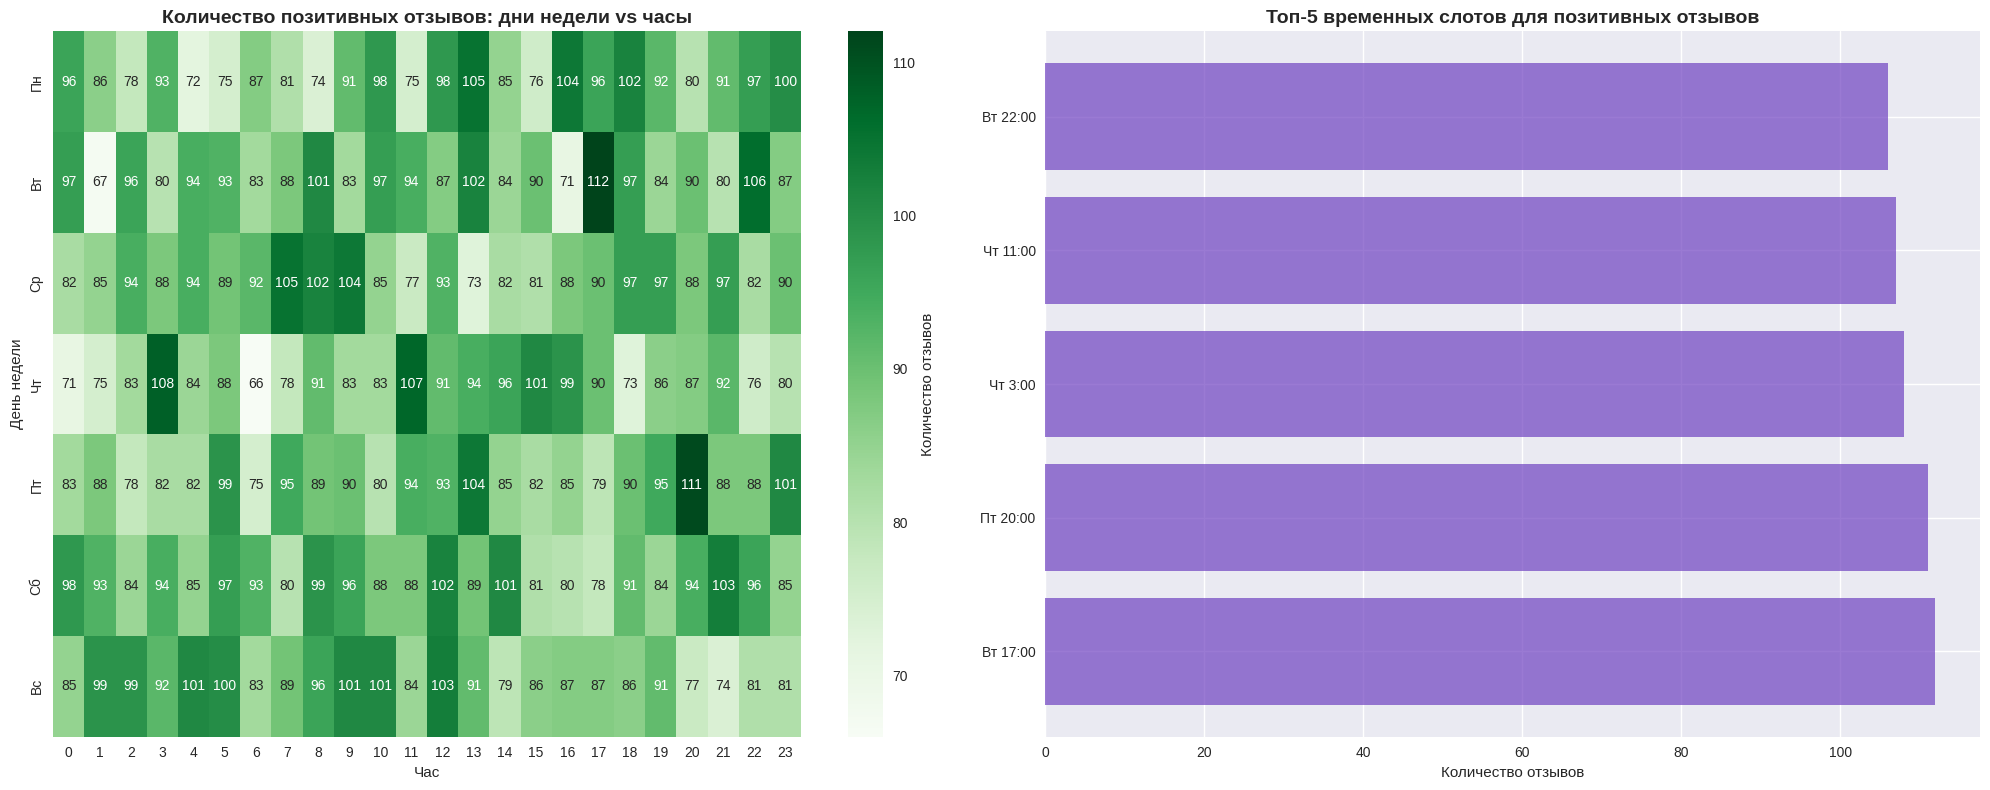

АНАЛИЗ ВРЕМЕННЫХ КЛАСТЕРОВ:


In [ ]:
# 5.1 Анализ недельных паттернов
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap по дням недели и часам (количество отзывов)
pivot_count = positive_df.pivot_table(
    values='id',
    index='day_of_week_num',
    columns='hour',
    aggfunc='count',
    fill_value=0
)

pivot_count = pivot_count.reindex(index=range(7))
pivot_count.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
pivot_count = pivot_count.reindex(columns=sorted(pivot_count.columns))

sns.heatmap(pivot_count, cmap='Greens', annot=True, fmt='.0f',
            cbar_kws={'label': 'Количество отзывов'}, ax=ax1)
ax1.set_title('Количество позитивных отзывов: дни недели vs часы', fontsize=14, fontweight='bold')
ax1.set_xlabel('Час')
ax1.set_ylabel('День недели')

# 5.2 Анализ пиковых периодов
weekly_pattern = positive_df.groupby(['day_of_week_num', 'hour']).size().reset_index()
weekly_pattern.columns = ['day', 'hour', 'count']
# Находим топ-5 самых продуктивных временных слотов
top_slots = weekly_pattern.nlargest(5, 'count')
times = [f"{day_names[int(row['day'])]} {int(row['hour'])}:00" for _, row in top_slots.iterrows()]
counts = top_slots['count'].values

ax2.barh(times, counts, color='#6F42C1', alpha=0.7)
ax2.set_title('Топ-5 временных слотов для позитивных отзывов', fontsize=14, fontweight='bold')
ax2.set_xlabel('Количество отзывов')

plt.tight_layout()
plt.show()

# 5.3 Анализ временных кластеров
print("=" * 60)
print("АНАЛИЗ ВРЕМЕННЫХ КЛАСТЕРОВ:")
print("=" * 60)
# Определяем кластеры времени
def get_time_cluster(hour):
    if 0 <= hour < 6:
        return 'Ночь'
    elif 6 <= hour < 12:
        return 'Утро'
    elif 12 <= hour < 18:
        return 'День'
    else:
        return 'Вечер'

positive_df['time_cluster'] = positive_df['hour'].apply(get_time_cluster)

In [ ]:
cluster_stats = positive_df.groupby('time_cluster').agg({
    'rating': ['mean', 'count'],
    'id': 'count'
}).round(2)

print(cluster_stats)

                rating          id
                  mean count count
time_cluster                      
Вечер         4.520042  3767  3767
День          4.515873  3780  3780
Ночь          4.495009  3707  3707
Утро          4.511746  3746  3746


<h1>Домашнее задание:</h1>
1. Проведите визуальный анализ данных комментариев, используя датасет reviews.csv или свой альтернативный вариант датасета. Не забудьте сделать предобработку текстового массива данных, которую делали на прошлых занятиях </br>
2. Опишите полученные результаты, сделайте выводы.</br>
3.* Сделайте POS-tagging и визуализируйте результат</br>
4.* Визуализируйте частотный анализ биграм</br>
